In [1]:
%pip install -q pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


# 05. Original metric: the Drawdown Recovery Score, and risk adjusted eras

This is the original contribution of this project. It is simple on
purpose, so a beginner can compute it by hand from a peak, a trough,
and a recovery date.

## The Drawdown Recovery Score, in plain words

Take one major fall, a fall of 20 percent or more from a peak.

Step 1, depth factor: if the fall was 20 percent, the depth factor is
0.80, because 80 percent of the value remained. If the fall was 50
percent, the depth factor is 0.50.

Step 2, speed factor: take the time from trough to recovery, in years,
add 1, and take the reciprocal. A recovery in 6 months is 0.5 years,
so the speed factor is 1 divided by 1.5, which is about 0.67. A
recovery in 5 years gives 1 divided by 6, which is about 0.17.

Step 3, score: multiply depth factor by speed factor, then multiply
by 100. The score runs from 0 to 100. Higher is better, meaning the
fall was shallower, or faster to heal, or both.

Example: a 20 percent fall recovered in 6 months scores about 53.
A 50 percent fall recovered in 60 months scores about 8.

Limits, stated honestly: the score does not measure what caused the
fall, it does not measure dividends, and it treats a fast shallow fall
as better than a slow deep fall even if the slow fall was caused by a
worse crisis. It is a descriptive summary, not a ranking of how bad a
crisis was for people. Use it to compare recovery shapes, not to judge
history.

## Risk adjusted era comparison

We also compare decades by return per unit of risk, which we defined
in notebook 03: compound annual growth divided by annualized
volatility. This answers a different question from raw growth: which
era gave the most growth for each unit of bumpiness?

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
ROOT = Path("..").resolve()
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
PROC = ROOT / "data" / "processed"
print("Charts will be saved to:", CHARTS)

Charts will be saved to: /home/hatch/workspace/repo-builds/finance-analytics/charts


In [3]:
major = pd.read_csv(PROC / "sp500_major_drawdowns.csv")
era = pd.read_csv(PROC / "sp500_by_era.csv")
print("Major drawdowns with Recovery Score:")
print(major[["peak_date", "trough_date", "recovery_date", "depth_pct", "decline_months", "recovery_months", "recovery_score"]].to_string(index=False))
print()
print("Era comparison:")
print(era.to_string(index=False))

Major drawdowns with Recovery Score:
 peak_date trough_date recovery_date  depth_pct  decline_months  recovery_months  recovery_score
2007-10-09  2009-03-09    2013-03-28     -56.78            17.0             48.6             8.6
2000-03-24  2002-10-09    2007-05-30     -49.15            30.5             55.7             9.0
1973-01-11  1974-10-03    1980-07-17     -48.20            20.7             69.4             7.6
2020-02-19  2020-03-23    2020-08-18     -33.92             1.1              4.9            46.9
1987-08-25  1987-12-04    1989-07-26     -33.51             3.3             19.7            25.2
1980-11-28  1982-08-12    1982-11-03     -27.11            20.4              2.7            59.5
1970-01-05  1970-05-26    1971-01-19     -25.86             4.6              7.8            44.9
2022-01-03  2022-10-12    2024-01-19     -25.43             9.3             15.2            32.9

Era comparison:
                       era  start_close  end_close  cagr_pct  annual_vol_

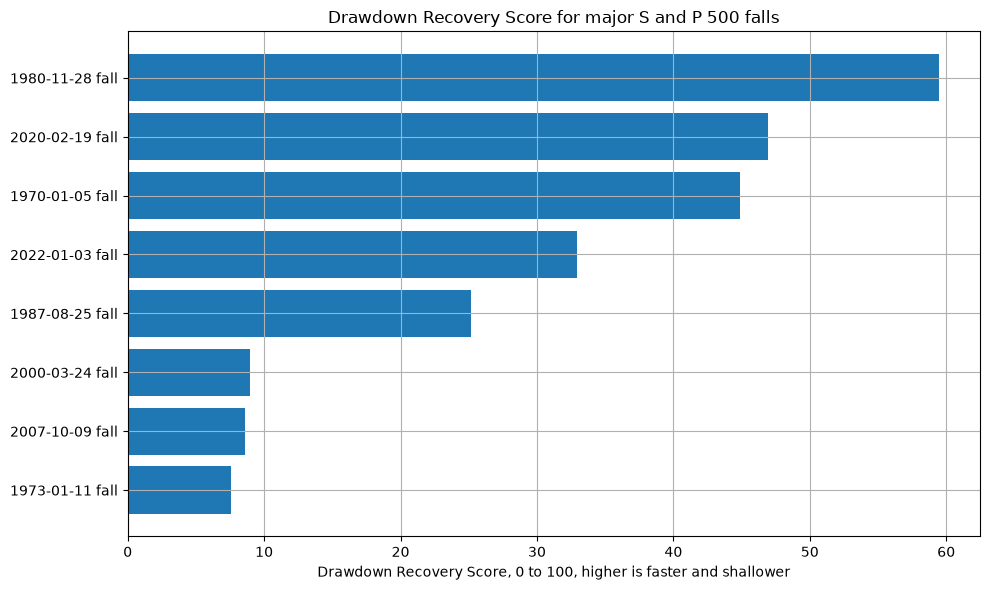

In [4]:
plot_major = major.sort_values("recovery_score", ascending=True)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(plot_major["peak_date"] + " fall", plot_major["recovery_score"])
ax.set_xlabel("Drawdown Recovery Score, 0 to 100, higher is faster and shallower")
ax.set_title("Drawdown Recovery Score for major S and P 500 falls")
plt.tight_layout()
plt.savefig(CHARTS / "05_recovery_score.png", dpi=150)
plt.show()

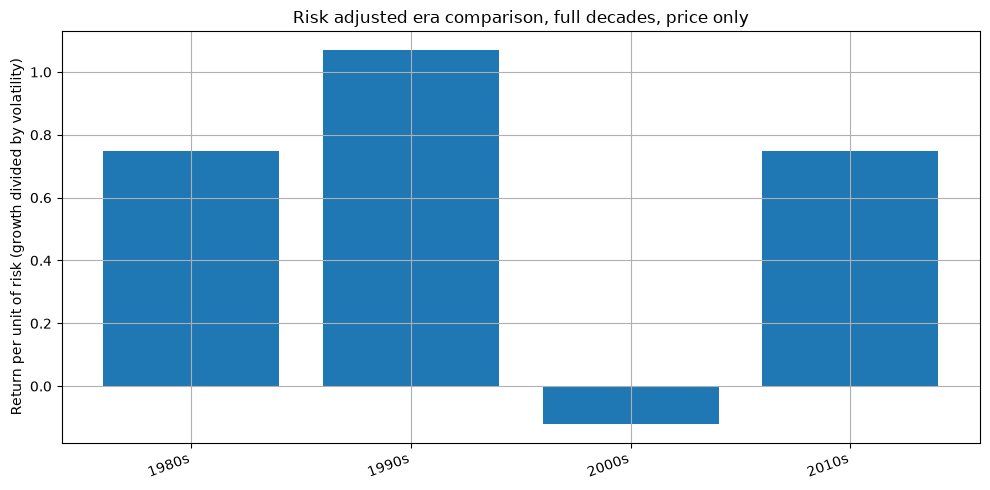

In [5]:
plot_era = era[~era["era"].str.contains("partial")]
fig, ax = plt.subplots()
ax.bar(plot_era["era"], plot_era["return_per_unit_risk"])
ax.set_ylabel("Return per unit of risk (growth divided by volatility)")
ax.set_title("Risk adjusted era comparison, full decades, price only")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(CHARTS / "05_era_risk_adjusted.png", dpi=150)
plt.show()

## What we learned, in plain words

The highest Recovery Score among major falls was the 1980 to 1982
episode, at 59.5. That fall was about 27.1 percent deep, but it
recovered from trough in only about 2.7 months, so it scores high
despite a long decline. The 2020 fall scored 46.9, because it was
deep, about 33.9 percent, but very fast to heal, about 4.9 months from
trough. The lowest scores were the three deepest falls: 1973 to 1974
at 7.6, 2007 to 2009 at 8.6, and 2000 to 2002 at 9.0. All three were
about 48 to 57 percent deep and took about 49 to 69 months from trough
to recover.

On the era comparison, the 1990s had the highest return per unit of
risk, at 1.07, followed by the 1980s and 2010s at 0.75 each. The 2000s
were the only full decade with a negative score, at minus 0.12, because
growth was negative while volatility was the highest of any full
decade, at about 22.2 percent.

The story angle is simple: raw growth alone hides the cost of getting
there. The 1990s did not just grow fast, they grew fast with moderate
bumpiness. The 2000s did not just grow slowly, they fell hard and took
years to heal. A portfolio story that only shows the end value, without
the drawdowns and the recovery times, is missing half the story.